# Categorising changes to skill files

This is a first review of 150 commits from the 10-skill pilot, with 15 commits per skill. I used the `SKILL.md` changes to assign categories. The commit title helped locate the change, but the label describes what changed in the skill file.

In [1]:
from pathlib import Path
import pandas as pd

file = Path("../data/gitskills/manual_category_review.csv")
if not file.exists():
    file = Path("data/gitskills/manual_category_review.csv")

review = pd.read_csv(file).fillna("")
review.shape

(150, 10)

## Category tree

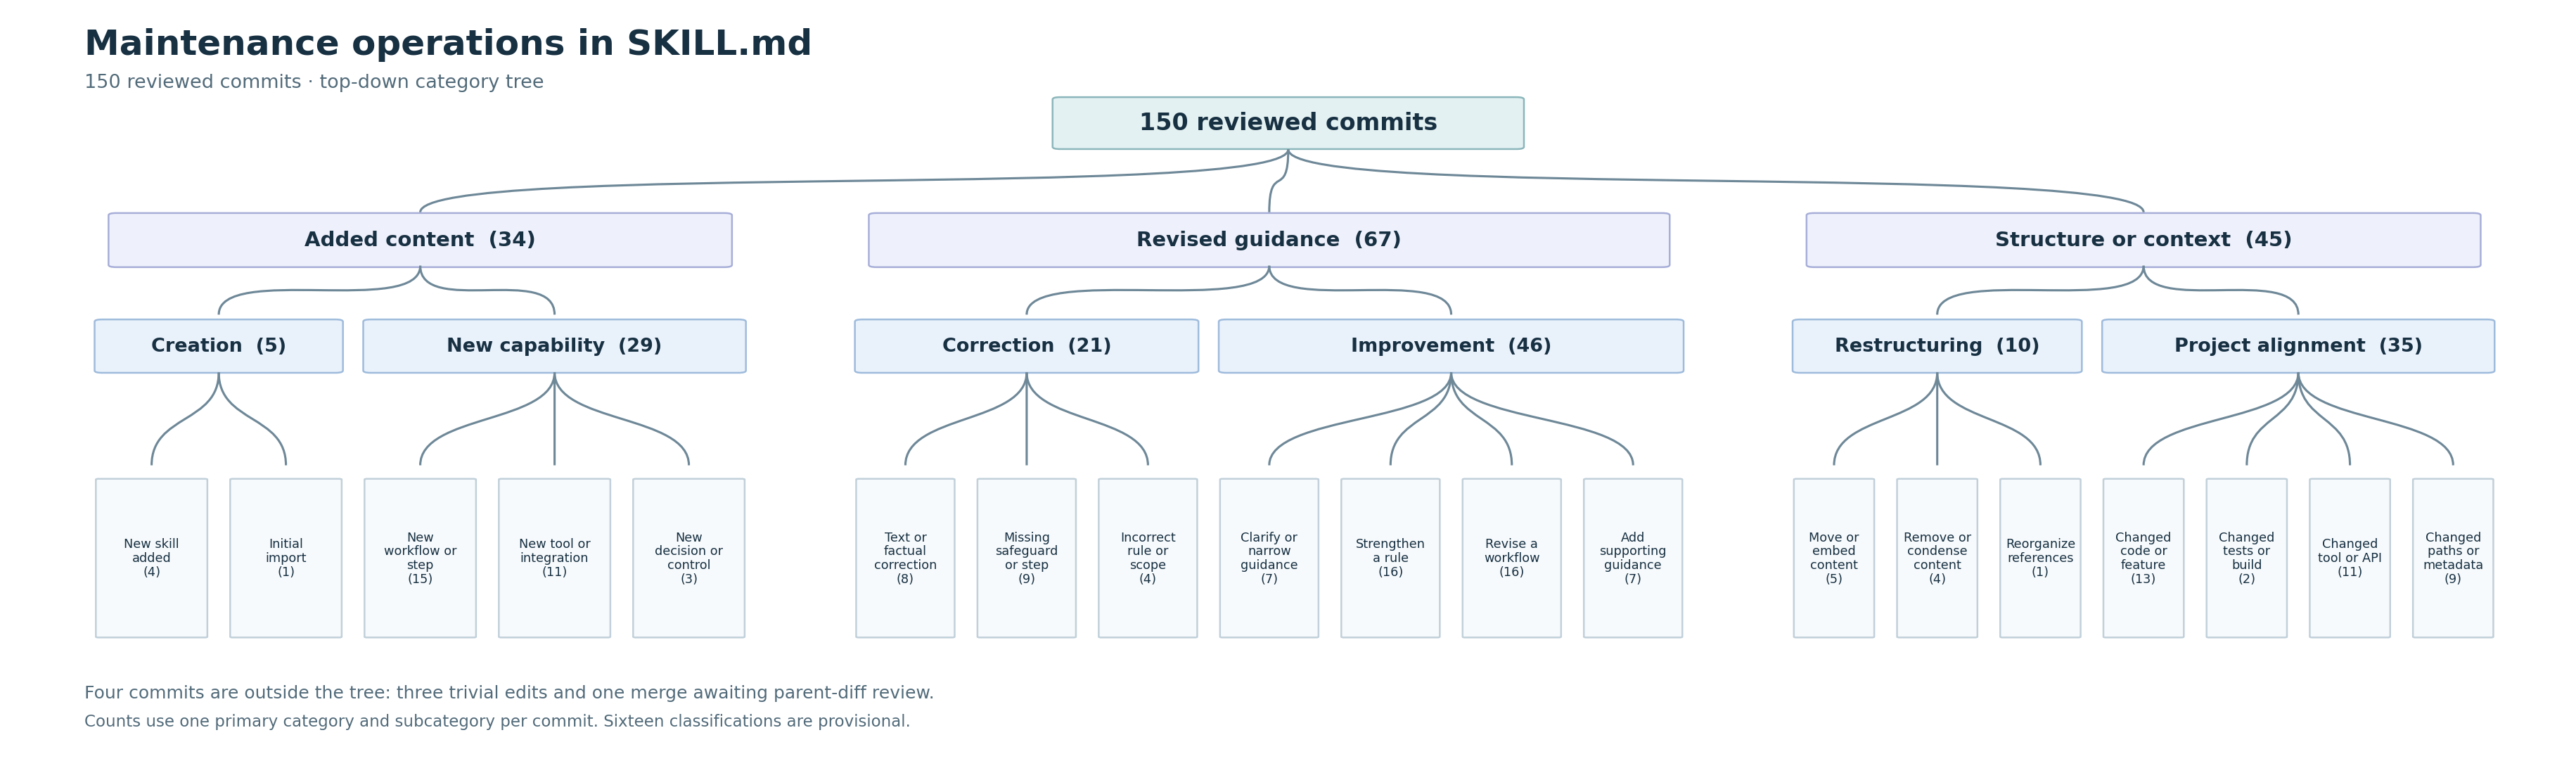

The first branch groups related operations: *Added content* contains creation and new capabilities; *Revised guidance* contains corrections and improvements; *Structure or context* contains restructuring and updates tied to project changes.

- Creation: means a new skill file.
- New capability: means a new action or workflow for the agent. 
- Correction: fixes something wrong. 
- Improvement: changes existing guidance.
- Restructuring: moves or simplifies instructions. 
- Project alignment: updates the skill after code, tests, tools, or paths change.

A whitespace-only change is marked **No substantive change** and sits outside the tree. A commit can also have a second category.

## Examples from the review

- [Creation](https://github.com/duc01226/EasyPlatform/commit/4f8f3500349dd95c98165fda8d6fcfebc28a2d77): the `refine` skill is created.
- [New capability](https://github.com/Wilder1222/superomni/commit/60ddcae41ba4a57c9fe124d3ea64ec95e9e88e87): the agent gets a procedure for resuming a session.
- [Correction](https://github.com/ericpzh/AC27LevelEditor/commit/51fb67e7c195260c8d5c715ca99ee647930a1cdd): broken text is repaired.
- [Improvement](https://github.com/gabb-software/gabb-cli/commit/17c4aa722b4c8010202c851ce1795e4c4f72cfee): the advice on when to use `gabb_structure` is made less rigid.
- [Restructuring](https://github.com/duc01226/EasyPlatform/commit/beba4ec75f069e73acc2bc9c16bb4d547f2cac1c): redundant links to shared protocols are removed.
- [Project alignment](https://github.com/Wilder1222/superomni/commit/4846ac0331797aca3023a2b95cdc6dfc8670bed0): paths are updated after supporting documents move.

The full list and my notes are in `data/gitskills/manual_category_review.csv`. The counts below describe only the 150 reviewed commits.

In [2]:
review["primary_category"].value_counts()

primary_category
Improvement              46
Project alignment        35
New capability           29
Correction               21
Restructuring            10
Creation                  5
No substantive change     3
Needs review              1
Name: count, dtype: int64

## Subcategories

The branch counts come from the `subcategory` column in the review table.

In [3]:
review.groupby(["primary_category", "subcategory"]).size().rename("commits").to_frame()

commits
primary_category      subcategory                        
Correction            Incorrect rule or scope           4
                      Missing safeguard or step         9
                      Text or factual correction        8
Creation              Initial import                    1
                      New skill added                   4
Improvement           Add supporting guidance           7
                      Clarify or narrow guidance        7
                      Revise a workflow                16
                      Strengthen a rule                16
Needs review                                            1
New capability        New decision or control           3
                      New tool or integration          11
                      New workflow or step             15
No substantive change                                   3
Project alignment     Changed code or feature          13
                      Changed paths or metadata         9
                      Changed tests or build            2
                      Changed tool or API              11
Restructuring         Move or embed content             5
                      Remove or condense content        4
                      Reorganize references             1

## Commits to check again

Some large edits mix categories, and one merge needs its parent diff checked. These labels are provisional. The short IDs are in the review table.

In [4]:
mixed = review[review["review_status"].str.contains("provisional|needs parent")].copy()
mixed["commit"] = mixed["commit_sha"].str[:8]
mixed[["commit", "primary_category", "secondary_category", "reason"]]

,commit,primary_category,secondary_category,reason
32,85f3e4bc,Improvement,Restructuring,add step tracking and reorganize existing guid...
33,9a9d2881,Improvement,Restructuring,add estimation and validation rules; remove em...
36,899fed93,Restructuring,Improvement,move detailed workflow into references; change...
71,510fbf58,Project alignment,Improvement,update cache and scan guidance
74,0d22facf,New capability,,add structured video-prompt workflow
79,7ab17d42,New capability,Project alignment,add Omni engine instructions
80,45815a5f,Improvement,Project alignment,change approval flow and video-type guidance
81,3de678c2,Restructuring,Improvement,replace structured-prompt section with older g...
82,fe297cba,Needs review,,merge snapshot needs parent-diff check
94,8df27a49,New capability,Improvement,expand refine skill with research and validati...


## Where this stands

This is a first coding pass for 150 commits. Of these, 146 have a main category and subcategory; three have no substantive change, and one merge still needs review. This is not a result for all 339. The 10 skills were chosen because they had many commits. The first 17 commits were also picked as examples, so category counts should not be treated as estimates for GitSkills. I still need to check the mixed edits and the merge commit.